# Exercise 2 — Image Blending Using OpenCV

**Author:** Mayank Mishra  
**Date:** 21 November 2026  
**Environment:** Python 3.12, OpenCV, Matplotlib

## Objective

Load two visually different images, resize them to identical dimensions, blend
them with a weighted sum, and save the blended result together with a
side-by-side comparison.

## Input images

- `image1.jpg` — mountain landscape, source photo ID 29 by Alexander Shustov.
- `image2.jpg` — Santorini cityscape, source photo ID 49 by Margaret Barley.

Both images were obtained from [Lorem Picsum](https://picsum.photos/), which
serves freely usable Unsplash photographs. The source and photographer are
recorded here for attribution.

## Expected outputs

- `outputs/Exercise2/blended_image.jpg`
- `outputs/Exercise2/comparison.png`

## 1. Import libraries and define paths

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "Exercise2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"OpenCV version: {cv2.__version__}")
print(f"Output folder : {OUTPUT_DIR}")

OpenCV version: 5.1.0
Output folder : C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise2


## 2. Load the two input images

In [2]:
img1_path = OUTPUT_DIR / "image1.jpg"
img2_path = OUTPUT_DIR / "image2.jpg"

img1 = cv2.imread(str(img1_path))
img2 = cv2.imread(str(img2_path))

if img1 is None or img2 is None:
    raise FileNotFoundError(
        "Could not load one or both images. "
        "Confirm that image1.jpg and image2.jpg exist in outputs/Exercise2."
    )

print(f"Image 1: shape={img1.shape}, dtype={img1.dtype}")
print(f"Image 2: shape={img2.shape}, dtype={img2.dtype}")

Image 1: shape=(900, 1600, 3), dtype=uint8
Image 2: shape=(900, 1600, 3), dtype=uint8


## 3. Resize both images to identical dimensions

In [3]:
TARGET_SIZE = (800, 450)  # width, height (16:9)

img1_resized = cv2.resize(img1, TARGET_SIZE, interpolation=cv2.INTER_AREA)
img2_resized = cv2.resize(img2, TARGET_SIZE, interpolation=cv2.INTER_AREA)

assert img1_resized.shape == img2_resized.shape
print(f"Resized shape: {img1_resized.shape}")

Resized shape: (450, 800, 3)


## 4. Apply weighted blending

In [4]:
alpha = 0.5
beta = 0.5
gamma = 0.0

blended = cv2.addWeighted(img1_resized, alpha, img2_resized, beta, gamma)
print(f"Blended shape: {blended.shape}, dtype: {blended.dtype}")
print(f"Formula: {alpha} * image1 + {beta} * image2 + {gamma}")

Blended shape: (450, 800, 3), dtype: uint8
Formula: 0.5 * image1 + 0.5 * image2 + 0.0


## 5. Display and save the originals and blended result

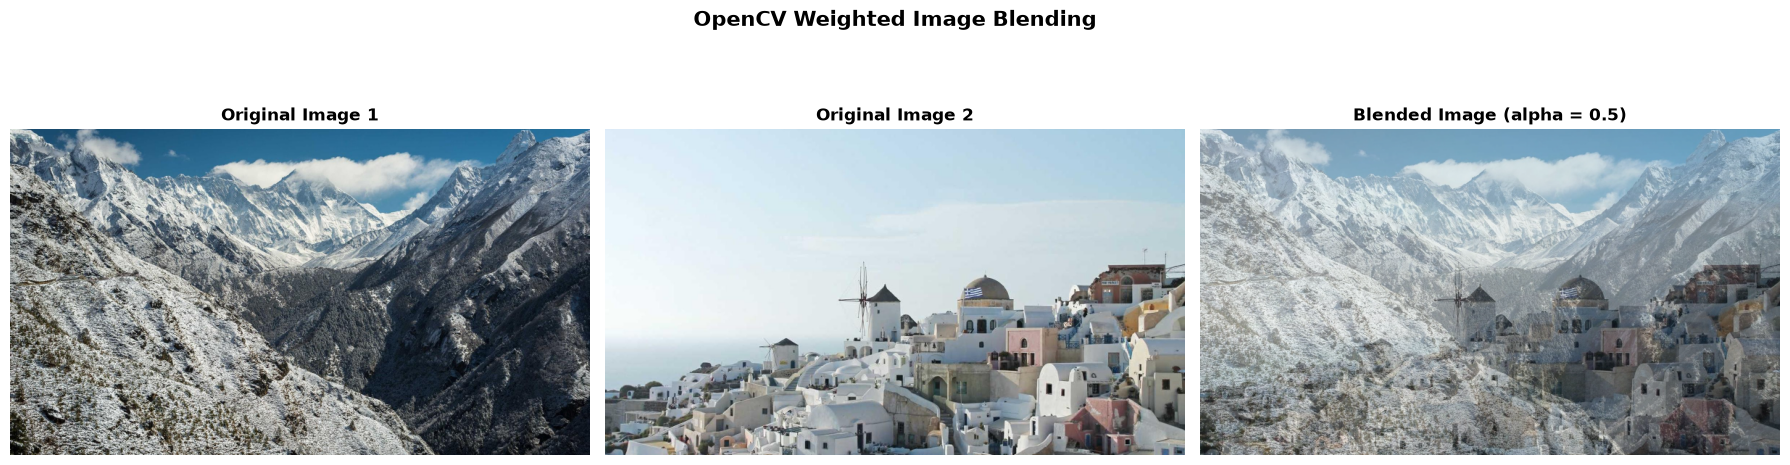

Saved: C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise2\blended_image.jpg
Saved: C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise2\comparison.png


In [5]:
img1_rgb = cv2.cvtColor(img1_resized, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2_resized, cv2.COLOR_BGR2RGB)
blend_rgb = cv2.cvtColor(blended, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, image, title in zip(
    axes,
    [img1_rgb, img2_rgb, blend_rgb],
    ["Original Image 1", "Original Image 2", "Blended Image (alpha = 0.5)"],
):
    ax.imshow(image)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.axis("off")

fig.suptitle("OpenCV Weighted Image Blending", fontsize=15, fontweight="bold")
fig.tight_layout()

comparison_path = OUTPUT_DIR / "comparison.png"
blended_path = OUTPUT_DIR / "blended_image.jpg"

fig.savefig(comparison_path, dpi=150, bbox_inches="tight")
cv2.imwrite(str(blended_path), blended, [int(cv2.IMWRITE_JPEG_QUALITY), 95])
plt.show()

print(f"Saved: {blended_path}")
print(f"Saved: {comparison_path}")

## 6. Verify the output files

In [6]:
for path in [blended_path, comparison_path]:
    print(f"{path.name:20s} {path.stat().st_size:>10,} bytes")

difference = cv2.absdiff(img1_resized, img2_resized)
print(f"Mean absolute pixel difference between inputs: {difference.mean():.2f}")

blended_image.jpg       197,250 bytes
comparison.png        2,153,014 bytes
Mean absolute pixel difference between inputs: 86.40


## Conclusion

- The two photographs were loaded successfully and resized to a common
  `800 × 450` canvas.
- `cv2.addWeighted()` computed `0.5 × image1 + 0.5 × image2 + 0`, producing a
  smooth 50/50 blend.
- The blended image and a three-panel comparison figure were saved in
  `outputs/Exercise2/`.
- Because OpenCV reads images in BGR order, each image was converted to RGB
  before Matplotlib display.

**Attribution:** Lorem Picsum photo IDs 29 (Alexander Shustov) and 49
(Margaret Barley), retrieved from <https://picsum.photos/>.